# bio_omics workflow - flowchart of the ETL pipeline

This notebook draws the end-to-end workflow of the repo: which source data
flows through which retrieval pipelines (`src/pipelines/`) into which SQL
tables and local outputs, and how the analysis notebooks consume them.

The flowchart is rendered with pure matplotlib and exported to
`doc/figures/workflow_flowchart.png`; the last cell verifies against the live
database that every table named in the diagram exists.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch


def box(ax, x, y, w, h, text, fc, ec='0.25', fs=9, weight='normal'):
    ax.add_patch(FancyBboxPatch(
        (x, y), w, h,
        boxstyle='round,pad=0.12,rounding_size=0.25',
        linewidth=1.2, edgecolor=ec, facecolor=fc))
    ax.text(x + w / 2, y + h / 2, text, ha='center', va='center',
            fontsize=fs, fontweight=weight)


def arrow(ax, x1, y1, x2, y2, color='0.25'):
    ax.add_patch(FancyArrowPatch(
        (x1, y1), (x2, y2), arrowstyle='-|>', mutation_scale=16,
        linewidth=1.6, color=color))


C_SOURCE = '#dbeafe'   # blue-ish
C_PIPE = '#dcfce7'     # green-ish
C_DB = '#fef9c3'       # yellow-ish
C_LOCAL = '#ffedd5'    # orange-ish
C_ANALYSIS = '#fce7f3' # pink-ish
C_OUT = '#e5e7eb'      # gray

saved figure: /home/yuan/bio/bio_omics/doc/figures/workflow_flowchart.png


PosixPath('/home/yuan/bio/bio_omics/doc/figures/workflow_flowchart.png')

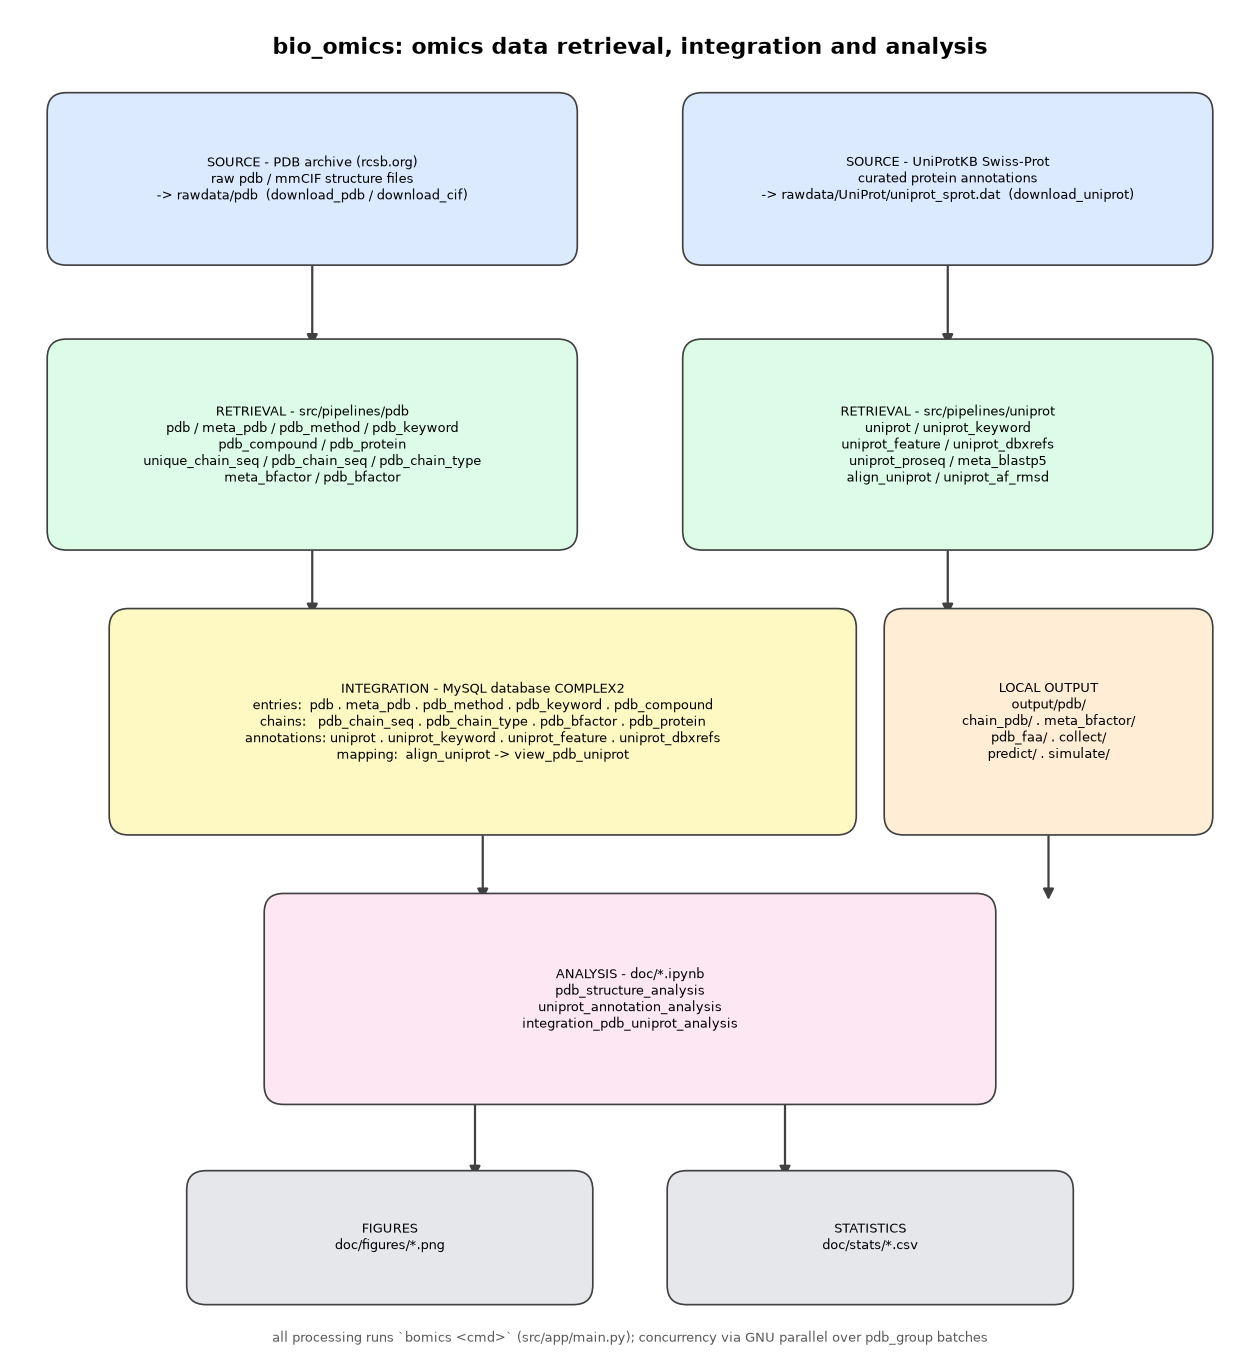

In [2]:
fig, ax = plt.subplots(figsize=(16, 17.5))
ax.set_xlim(0, 16)
ax.set_ylim(0, 17.5)
ax.axis('off')

ax.text(8, 17.0, 'bio_omics: omics data retrieval, integration and analysis',
        ha='center', va='center', fontsize=16, fontweight='bold')

# ---------------- layer 1: sources ----------------
box(ax, 0.6, 14.3, 6.6, 2.0,
    'SOURCE - PDB archive (rcsb.org)\n'
    'raw pdb / mmCIF structure files\n'
    '-> rawdata/pdb  (download_pdb / download_cif)', C_SOURCE)
box(ax, 8.8, 14.3, 6.6, 2.0,
    'SOURCE - UniProtKB Swiss-Prot\n'
    'curated protein annotations\n'
    '-> rawdata/UniProt/uniprot_sprot.dat  (download_uniprot)', C_SOURCE)

arrow(ax, 3.9, 14.2, 3.9, 13.1)
arrow(ax, 12.1, 14.2, 12.1, 13.1)

# ---------------- layer 2: retrieval pipelines ----------------
box(ax, 0.6, 10.6, 6.6, 2.5,
    'RETRIEVAL - src/pipelines/pdb\n'
    'pdb / meta_pdb / pdb_method / pdb_keyword\n'
    'pdb_compound / pdb_protein\n'
    'unique_chain_seq / pdb_chain_seq / pdb_chain_type\n'
    'meta_bfactor / pdb_bfactor', C_PIPE)
box(ax, 8.8, 10.6, 6.6, 2.5,
    'RETRIEVAL - src/pipelines/uniprot\n'
    'uniprot / uniprot_keyword\n'
    'uniprot_feature / uniprot_dbxrefs\n'
    'uniprot_proseq / meta_blastp5\n'
    'align_uniprot / uniprot_af_rmsd', C_PIPE)

arrow(ax, 3.9, 10.5, 3.9, 9.6)
arrow(ax, 12.1, 10.5, 12.1, 9.6)

# ---------------- layer 3: storage ----------------
box(ax, 1.4, 6.9, 9.4, 2.7,
    'INTEGRATION - MySQL database COMPLEX2\n'
    'entries:  pdb . meta_pdb . pdb_method . pdb_keyword . pdb_compound\n'
    'chains:   pdb_chain_seq . pdb_chain_type . pdb_bfactor . pdb_protein\n'
    'annotations: uniprot . uniprot_keyword . uniprot_feature . uniprot_dbxrefs\n'
    'mapping:  align_uniprot -> view_pdb_uniprot', C_DB)
box(ax, 11.4, 6.9, 4.0, 2.7,
    'LOCAL OUTPUT\n'
    'output/pdb/\n'
    'chain_pdb/ . meta_bfactor/\n'
    'pdb_faa/ . collect/\n'
    'predict/ . simulate/', C_LOCAL)

arrow(ax, 6.1, 6.8, 6.1, 5.9)
arrow(ax, 13.4, 6.8, 13.4, 5.9)

# ---------------- layer 4: analysis ----------------
box(ax, 3.4, 3.4, 9.2, 2.5,
    'ANALYSIS - doc/*.ipynb\n'
    'pdb_structure_analysis\n'
    'uniprot_annotation_analysis\n'
    'integration_pdb_uniprot_analysis', C_ANALYSIS)

arrow(ax, 6.0, 3.3, 6.0, 2.3)
arrow(ax, 10.0, 3.3, 10.0, 2.3)

# ---------------- layer 5: results ----------------
box(ax, 2.4, 0.8, 5.0, 1.5,
    'FIGURES\ndoc/figures/*.png', C_OUT)
box(ax, 8.6, 0.8, 5.0, 1.5,
    'STATISTICS\ndoc/stats/*.csv', C_OUT)

ax.text(8, 0.25, 'all processing runs `bomics <cmd>` (src/app/main.py); '
        'concurrency via GNU parallel over pdb_group batches',
        ha='center', va='center', fontsize=9, color='0.35')

fig.suptitle('')
save = Path('figures')  # resolved by nb_utils when executed in notebooks
import sys
sys.path.insert(0, str(Path.cwd() / 'doc' if (Path.cwd() / 'doc' / 'nb_utils.py').is_file()
                      else Path.cwd()))
from nb_utils import save_fig
save_fig(fig, 'workflow_flowchart')

### Reading the flowchart

- **Sources** hold raw downloads: structure files (`rawdata/pdb`) and the
  curated Swiss-Prot flat file (`rawdata/UniProt`).
- **Retrieval** pipelines (`bomics <cmd>` entry points in `src/app/main.py`)
  parse the raw data in parallel over `pdb_group` batches and push records as
  key-value entities.
- **Integration** stores everything in MySQL `COMPLEX2`, where the view
  `view_pdb_uniprot` bridges structure (PDB chains) and annotation
  (Swiss-Prot accessions); processed files are mirrored under `output/pdb`.
- **Analysis** notebooks in `doc/` query the tables and export figures
  (`doc/figures/*.png`) and statistical tables (`doc/stats/*.csv`).

## Verify the flowchart against the live database

Every table named in the diagram must exist in COMPLEX2. The check below
lists missing objects (expected: none).

In [3]:
import sys
from pathlib import Path
import pandas as pd

def _locate_doc_dir():
    for start in (Path.cwd(), *Path.cwd().parents):
        if (start / 'doc' / 'nb_utils.py').is_file():
            return start / 'doc'
    return Path.cwd()

doc_dir = _locate_doc_dir()
sys.path.insert(0, str(doc_dir))
from nb_utils import query_df, save_csv

named_tables = [
    'pdb', 'meta_pdb', 'pdb_method', 'pdb_keyword', 'pdb_compound',
    'pdb_protein', 'pdb_chain_seq', 'pdb_chain_type', 'meta_bfactor',
    'pdb_bfactor', 'uniprot', 'uniprot_keyword', 'uniprot_feature',
    'uniprot_dbxrefs', 'uniprot_proseq', 'align_uniprot', 'view_pdb_uniprot',
]
db_tables = set(query_df('SHOW TABLES').iloc[:, 0])
verification = pd.DataFrame([
    {'object': t, 'exists': t in db_tables} for t in named_tables])
save_csv(verification, 'workflow_flowchart_verification')
missing = verification[~verification['exists']]
print('all flowchart objects exist' if missing.empty else f'MISSING: {missing}')
verification

saved table: /home/yuan/bio/bio_omics/doc/stats/workflow_flowchart_verification.csv  shape=(17, 2)
all flowchart objects exist


,object,exists
0,pdb,True
1,meta_pdb,True
2,pdb_method,True
3,pdb_keyword,True
4,pdb_compound,True
5,pdb_protein,True
6,pdb_chain_seq,True
7,pdb_chain_type,True
8,meta_bfactor,True
9,pdb_bfactor,True


## Summary

- `doc/figures/workflow_flowchart.png` - rendered ETL flowchart
- `doc/stats/workflow_flowchart_verification.csv` - proof that every table in
  the diagram exists in the live database